# Exercício 25 — Dados de leucemia (Feigl e Zelen, 1965)

**Objetivo:** explicar o tempo médio de sobrevivência (em semanas) após o diagnóstico em função de $\log(\text{WBC})$ e do fator AG (1 = positivo, 0 = negativo), supondo que o tempo segue distribuição **gama**.

Roteiro:
1. Leitura dos dados
2. Análise descritiva
3. Ajuste do modelo gama
4. Análise de diagnóstico
5. Ajuste no GAMLSS: `plot`, `wp` e `term.plot`
6. Interpretação das estimativas

## 1. Leitura dos dados

Os dados da tabela estão digitados abaixo. Se você tiver o `sobrev.txt`, pode usar o `read.table` comentado (confira a ordem das colunas no arquivo).

In [1]:
# Caminho da pasta MLG (troque pelo do seu computador)
caminho <- "C:/Users/Marcelo/Downloads/uns pdfs/ufscar/2026 02/MLG/"
envelopes <- paste0(caminho, "Envelopes/")

# Dados da tabela do enunciado
wbc_pos   <- c(2300, 750, 4300, 2600, 6000, 10500, 10000, 17000, 5400, 7000,
               9400, 32000, 35000, 100000, 100000, 52000, 100000)
tempo_pos <- c(65, 156, 100, 134, 16, 108, 121, 4, 39, 143, 56, 26, 22, 1, 1, 5, 65)

wbc_neg   <- c(4400, 3000, 4000, 1500, 9000, 5300, 10000, 19000, 27000, 28000,
               31000, 26000, 21000, 79000, 100000, 100000)
tempo_neg <- c(56, 65, 17, 7, 16, 22, 3, 4, 2, 3, 8, 4, 3, 30, 4, 43)

sobrev <- data.frame(tempo = c(tempo_pos, tempo_neg),
                     WBC   = c(wbc_pos, wbc_neg),
                     AG    = c(rep(1, 17), rep(0, 16)))   # 1 = positivo, 0 = negativo

# Alternativa com o arquivo do livro:
# sobrev <- read.table(paste0(caminho, "sobrev.txt"), head=F, sep="",
#                      col.names=c("WBC","tempo","AG"))

# Covariável do enunciado: log(WBC)
sobrev$lwbc <- log(sobrev$WBC)
sobrev

tempo,WBC,AG,lwbc
<dbl>,<dbl>,<dbl>,<dbl>
65,2300,1,7.740664
156,750,1,6.620073
100,4300,1,8.366370
134,2600,1,7.863267
16,6000,1,8.699515
108,10500,1,9.259131
121,10000,1,9.210340
4,17000,1,9.740969
39,5400,1,8.594154


## 2. Análise descritiva

A ideia é ver (i) a assimetria do tempo, que justifica a gama, e (ii) como o tempo se relaciona com $\log(\text{WBC})$ em cada grupo de AG. Como usaremos ligação log, olhamos também $\log(\text{tempo})$.

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   1.00    4.00   22.00   40.88   65.00  156.00 

,AG,tempo.mean,tempo.sd,tempo.length
,<dbl>,<dbl>,<dbl>,<dbl>
1,0,17.93750,20.30261,16
2,1,62.47059,54.35315,17


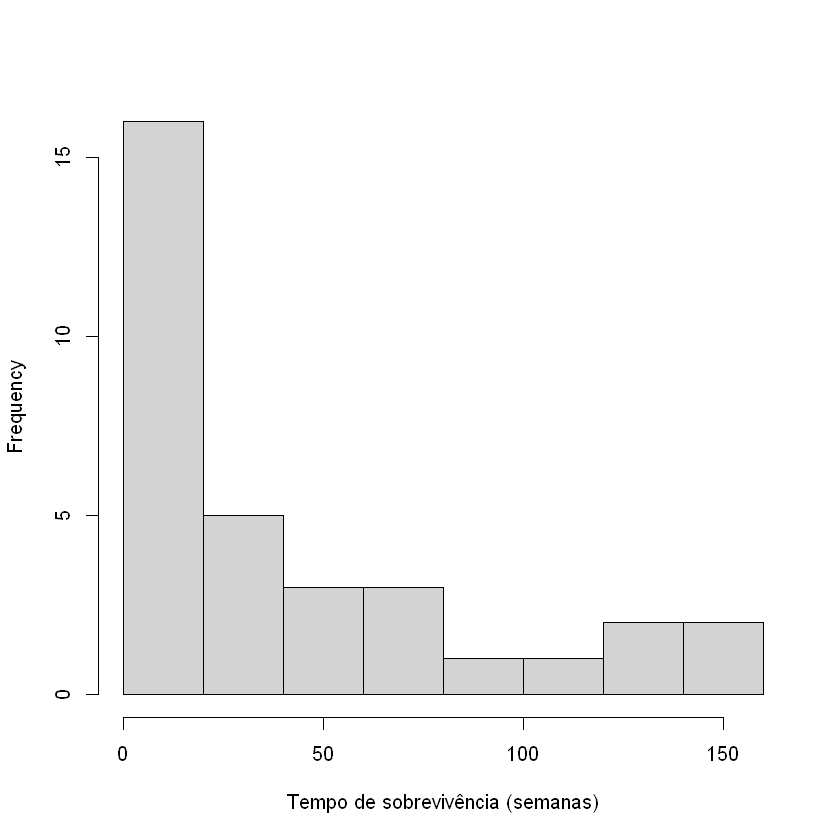

In [2]:
# Distribuição do tempo: assimetria à direita
hist(sobrev$tempo, main="", xlab="Tempo de sobrevivência (semanas)")
summary(sobrev$tempo)

# Médias e desvios por grupo de AG
library(doBy)
summaryBy(tempo ~ factor(AG), data=sobrev, FUN=c(mean, sd, length))

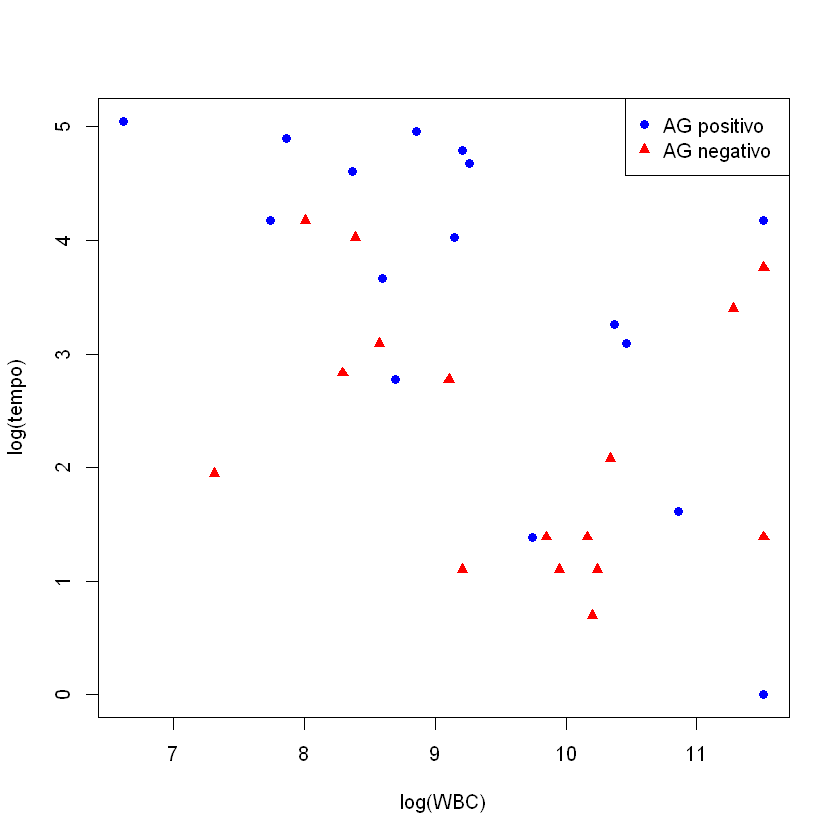

In [3]:
# Relação com log(WBC), separando os grupos (azul = AG positivo, vermelho = AG negativo)
plot(sobrev$lwbc, log(sobrev$tempo), pch=ifelse(sobrev$AG==1, 16, 17),
     col=ifelse(sobrev$AG==1, "blue", "red"),
     xlab="log(WBC)", ylab="log(tempo)")
legend("topright", c("AG positivo","AG negativo"), pch=c(16,17), col=c("blue","red"))

**O que esperar:** o tempo é bem assimétrico, e os pacientes AG positivo sobrevivem, em média, bem mais que os AG negativo. Nos dois grupos, $\log(\text{tempo})$ tende a cair quando $\log(\text{WBC})$ aumenta. Se as inclinações forem diferentes entre os grupos, haveria interação; isso é testado no item 3.

## 3. Ajuste do modelo gama

Modelo proposto:

$$Y_i \sim \text{Gama}(\mu_i, \phi), \qquad \log(\mu_i) = \beta_0 + \beta_1 \log(\text{WBC}_i) + \beta_2\,\text{AG}_i.$$

Primeiro ajustamos o modelo com interação para testar se o efeito de $\log(\text{WBC})$ é o mesmo nos dois grupos.

In [4]:
# Modelo com interação: efeito de log(WBC) diferente em cada grupo de AG
aj1_sobrev <- glm(tempo ~ lwbc + AG + lwbc*AG, family=Gamma(link="log"), data=sobrev)
summary(aj1_sobrev)

# Modelo sem interação (aditivo)
aj2_sobrev <- glm(tempo ~ lwbc + AG, family=Gamma(link="log"), data=sobrev)
summary(aj2_sobrev)


Call:
glm(formula = tempo ~ lwbc + AG + lwbc * AG, family = Gamma(link = "log"), 
    data = sobrev)

Coefficients:
            Estimate Std. Error t value Pr(>|t|)  
(Intercept)   4.3435     2.0773   2.091   0.0454 *
lwbc         -0.1540     0.2141  -0.719   0.4777  
AG            4.1347     2.7155   1.523   0.1387  
lwbc:AG      -0.3278     0.2820  -1.162   0.2545  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 1.116173)

    Null deviance: 58.138  on 32  degrees of freedom
Residual deviance: 38.555  on 29  degrees of freedom
AIC: 301.74

Number of Fisher Scoring iterations: 11



Call:
glm(formula = tempo ~ lwbc + AG, family = Gamma(link = "log"), 
    data = sobrev)

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)   5.8154     1.3487   4.312 0.000161 ***
lwbc         -0.3044     0.1375  -2.213 0.034617 *  
AG            1.0176     0.3642   2.794 0.008982 ** 
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 1.087715)

    Null deviance: 58.138  on 32  degrees of freedom
Residual deviance: 40.319  on 30  degrees of freedom
AIC: 301.49

Number of Fisher Scoring iterations: 8


In [5]:
# H0: não há interação. Teste F, pois phi é estimado.
anova(aj2_sobrev, aj1_sobrev, test="F")

# Teste da razão de verossimilhanças (como nos códigos do professor)
library(lmtest)
lrtest(aj2_sobrev, aj1_sobrev)

,Resid. Df,Resid. Dev,Df,Deviance,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,30,40.31909,NA,NA,NA,NA
2,29,38.55460,1,1.764485,1.580835,0.2186722


Carregando pacotes exigidos: zoo


Anexando pacote: 'zoo'


Os seguintes objetos são mascarados por 'package:base':

    as.Date, as.Date.numeric




,#Df,LogLik,Df,Chisq,Pr(>Chisq)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,4,-146.7436,NA,NA,NA
2,5,-145.8723,1,1.742576,0.1868127


**Resultado:** a interação não é significativa (teste F: p ≈ 0,22), então ficamos com o modelo aditivo `aj2_sobrev`. Nele, as duas variáveis são significativas a 5%:

| | Estimativa | Erro padrão | p-valor |
|---|---|---|---|
| Intercepto | 5,815 | 1,349 | < 0,001 |
| log(WBC) | −0,304 | 0,138 | 0,035 |
| AG | 1,018 | 0,364 | 0,009 |

A dispersão estimada pelo R é 1,088, ou seja, $\hat\phi = 1/1{,}088 \approx 0{,}92$ na parametrização do livro. Um $\phi$ perto de 1 indica que a distribuição está próxima da exponencial.

## 4. Análise de diagnóstico

Mesmo roteiro dos códigos do professor: alavanca, resíduo deviance, resíduo de Pearson, distância de Cook e envelope.

No notebook, `windows()` e `identify()` não funcionam (eles abrem janelas e esperam cliques). No lugar do `identify`, o código escreve o número da observação nos pontos que mais se destacam.

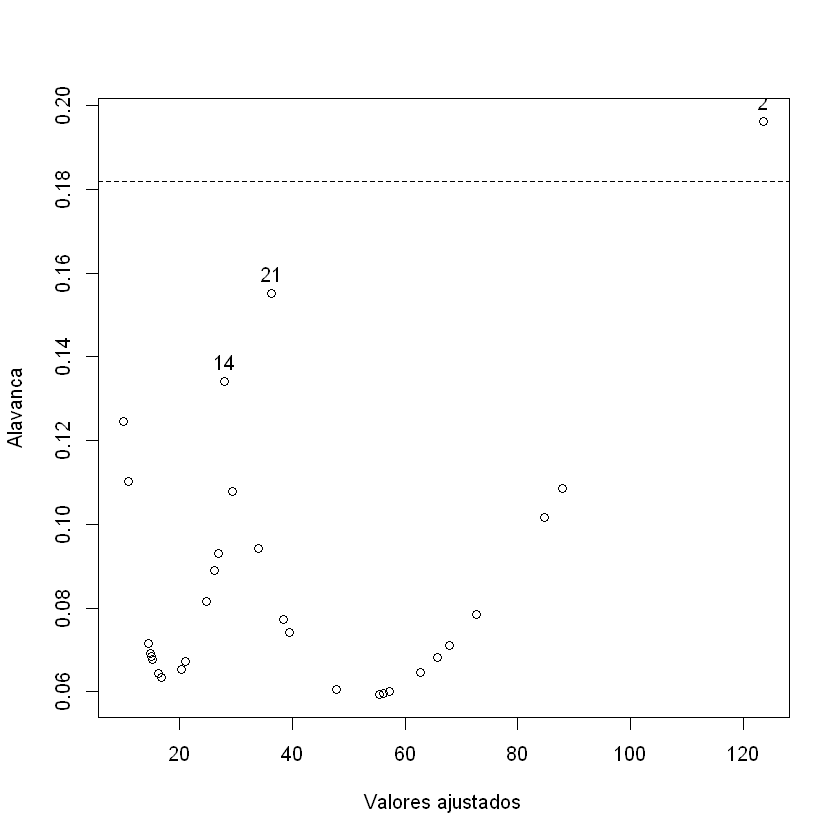

In [6]:
X <- model.matrix(aj2_sobrev)   # matriz modelo
w <- aj2_sobrev$weights         # pesos do processo iterativo
W <- diag(w)

# Pontos alavanca: diagonal de H. Referência: 2p/n
auxh <- solve(t(X)%*%W%*%X)
H <- sqrt(W)%*%X%*%auxh%*%t(X)%*%sqrt(W)
h <- diag(H)
plot(fitted(aj2_sobrev), h, xlab="Valores ajustados", ylab="Alavanca")
abline(h=2*ncol(X)/nrow(X), lty=2)
destaque <- order(h, decreasing=TRUE)[1:3]            # substitui o identify
text(fitted(aj2_sobrev)[destaque], h[destaque], labels=destaque, pos=3)

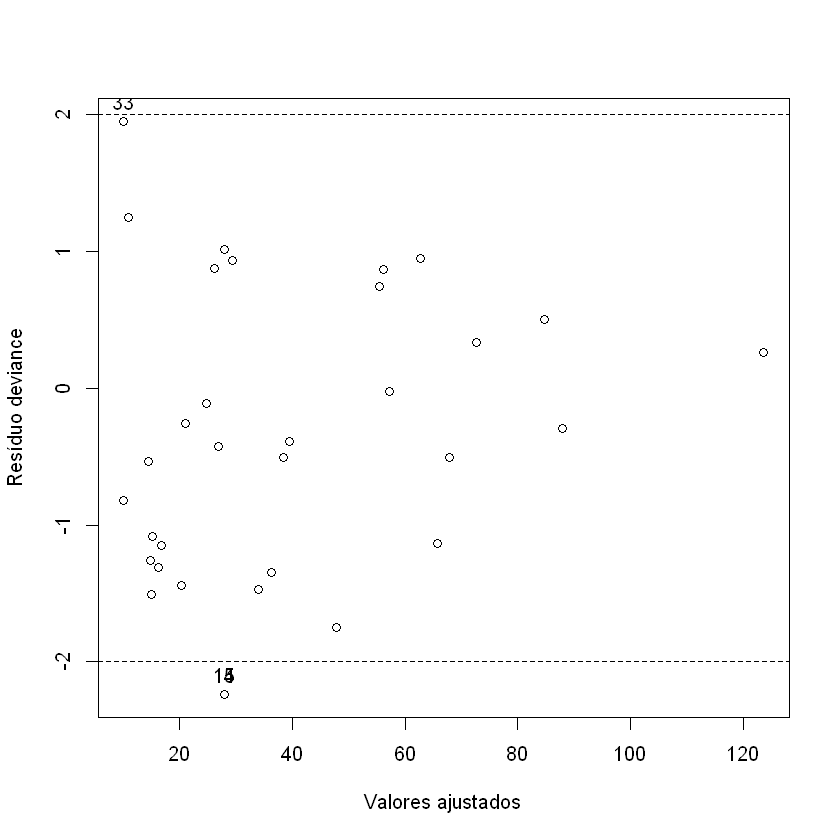

In [7]:
# Resíduo componente do desvio padronizado. Referência: (-2, 2)
aux_tdi <- resid(aj2_sobrev, type='deviance')
aux_fi <- summary(aj2_sobrev)
fi <- 1/aux_fi$dispersion
tdi <- aux_tdi*sqrt(fi/(1-h))
plot(fitted(aj2_sobrev), tdi, xlab="Valores ajustados", ylab="Resíduo deviance")
abline(h=c(-2,2), lty=2)
destaque <- order(abs(tdi), decreasing=TRUE)[1:3]
text(fitted(aj2_sobrev)[destaque], tdi[destaque], labels=destaque, pos=3)

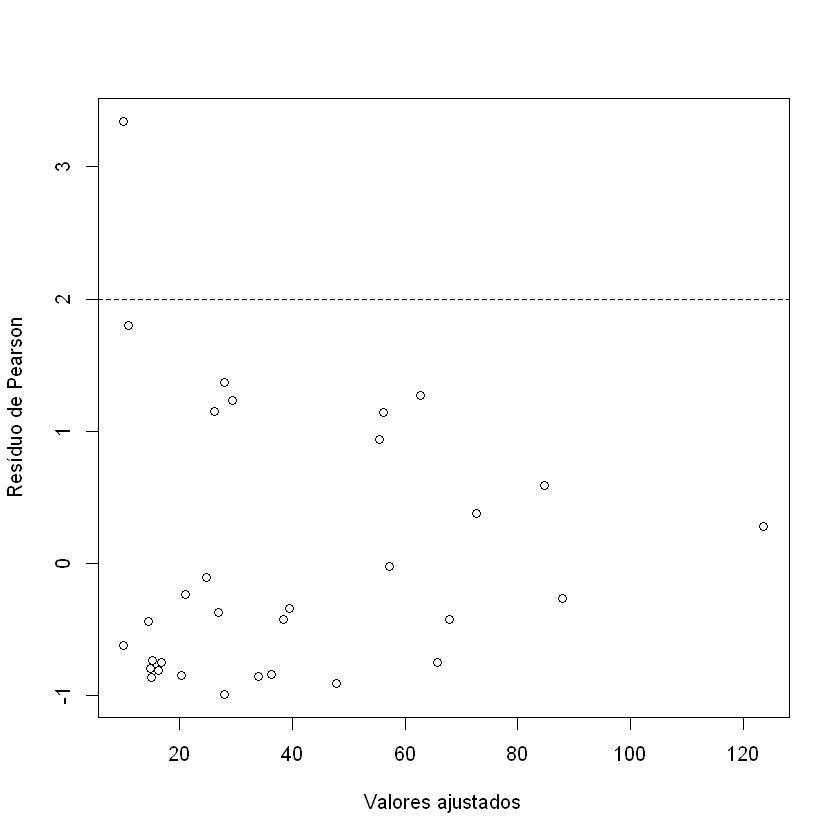

In [8]:
# Resíduo de Pearson padronizado
aux_tsi <- resid(aj2_sobrev, type='pearson')
tsi <- aux_tsi*sqrt(fi/(1-h))
plot(fitted(aj2_sobrev), tsi, xlab="Valores ajustados", ylab="Resíduo de Pearson")
abline(h=c(-2,2), lty=2)

,tempo,WBC,AG,lwbc,h,tdi,ldi
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
33,43,100000,0,11.513,0.125,1.952,1.594
31,30,79000,0,11.277,0.110,1.245,0.400
17,65,100000,1,11.513,0.134,1.014,0.291
19,65,3000,0,8.006,0.108,0.931,0.185
14,1,100000,1,11.513,0.134,-2.241,0.153


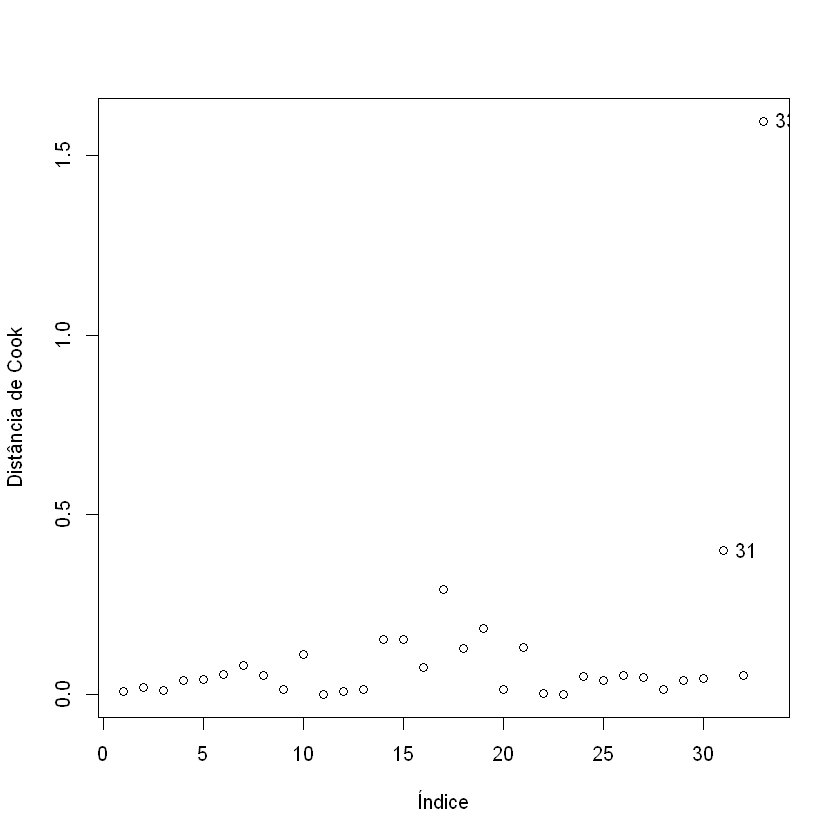

In [9]:
# Distância de Cook: influência de cada ponto nas estimativas
ldi <- h*(tsi^2)/(1 - h)
plot(ldi, xlab="Índice", ylab="Distância de Cook")
destaque <- order(ldi, decreasing=TRUE)[1:2]
text(destaque, ldi[destaque], labels=destaque, pos=4)

# Tabela dos pontos mais influentes
round(cbind(sobrev, h, tdi, ldi), 3)[order(ldi, decreasing=TRUE)[1:5], ]

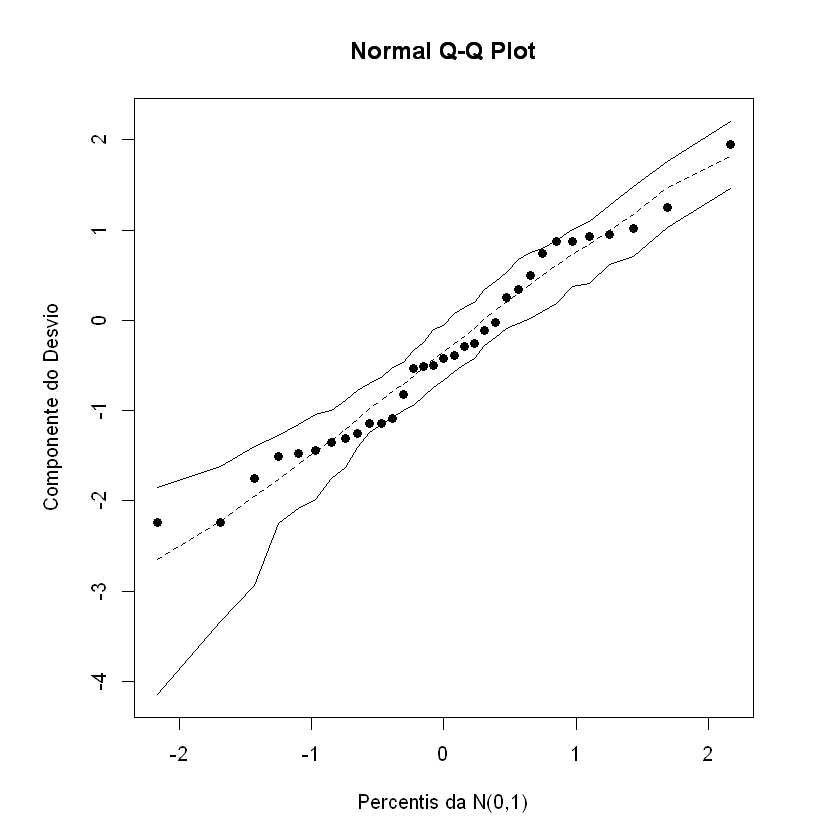

In [10]:
# Envelope (função do professor, na pasta MLG/Envelopes)
fit.model <- aj2_sobrev
source(paste0(envelopes, "envelope_gama.R"))

**O que aparece no diagnóstico:**

- **Alavanca:** nenhum ponto passa muito da referência $2p/n = 0{,}18$; as maiores alavancas (≈ 0,13) são pacientes com WBC = 100000, o valor extremo da covariável.
- **Resíduo deviance:** só a observação **14** (AG positivo, WBC = 100000, tempo = 1 semana) fica um pouco abaixo de −2. É um paciente com prognóstico bom pelo grupo, mas que sobreviveu muito pouco.
- **Distância de Cook:** a observação **33** (AG negativo, WBC = 100000, tempo = 43 semanas) é a mais influente, bem acima das demais. Ela sobreviveu muito mais do que o modelo prevê para o seu perfil.
- **Envelope:** confira se os pontos ficam dentro das bandas; se ficarem, não há evidência contra a distribuição gama.

Para avaliar a influência, reajustamos o modelo sem as observações destacadas:

In [11]:
aj2_sobrev_sem33 <- glm(tempo ~ lwbc + AG, family=Gamma(link="log"), data=sobrev, subset=-c(33))
summary(aj2_sobrev_sem33)

aj2_sobrev_sem14 <- glm(tempo ~ lwbc + AG, family=Gamma(link="log"), data=sobrev, subset=-c(14))
summary(aj2_sobrev_sem14)

aj2_sobrev_sem14_33 <- glm(tempo ~ lwbc + AG, family=Gamma(link="log"), data=sobrev, subset=-c(14,33))
summary(aj2_sobrev_sem14_33)


Call:
glm(formula = tempo ~ lwbc + AG, family = Gamma(link = "log"), 
    data = sobrev, subset = -c(33))

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)   6.7070     1.3877   4.833 4.03e-05 ***
lwbc         -0.4241     0.1433  -2.959  0.00609 ** 
AG            1.2294     0.3722   3.303  0.00254 ** 
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 1.102961)

    Null deviance: 58.136  on 31  degrees of freedom
Residual deviance: 35.022  on 29  degrees of freedom
AIC: 286.59

Number of Fisher Scoring iterations: 7



Call:
glm(formula = tempo ~ lwbc + AG, family = Gamma(link = "log"), 
    data = sobrev, subset = -c(14))

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)   5.4497     1.3469   4.046 0.000353 ***
lwbc         -0.2675     0.1375  -1.945 0.061542 .  
AG            1.1070     0.3565   3.105 0.004220 ** 
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 1.000993)

    Null deviance: 52.639  on 31  degrees of freedom
Residual deviance: 35.449  on 29  degrees of freedom
AIC: 294.57

Number of Fisher Scoring iterations: 9



Call:
glm(formula = tempo ~ lwbc + AG, family = Gamma(link = "log"), 
    data = sobrev, subset = -c(14, 33))

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)   6.3547     1.3826   4.596 8.36e-05 ***
lwbc         -0.3873     0.1430  -2.708  0.01142 *  
AG            1.2980     0.3612   3.593  0.00124 ** 
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 1.004317)

    Null deviance: 52.639  on 30  degrees of freedom
Residual deviance: 30.688  on 28  degrees of freedom
AIC: 279.88

Number of Fisher Scoring iterations: 7


**Conclusão da análise de influência:**

- **Sem a observação 33:** o coeficiente de log(WBC) passa de −0,304 para −0,424 e o de AG de 1,018 para 1,229. Os efeitos ficam mais fortes e continuam significativos.
- **Sem a observação 14:** o coeficiente de log(WBC) passa para −0,268 e o p-valor sobe para ≈ 0,06, ficando no limite da significância a 5%. O efeito de AG não se altera.
- **Sem as duas:** log(WBC) = −0,387 (p ≈ 0,01) e AG continua significativo.

Nenhuma retirada muda o sinal dos efeitos, e não há motivo clínico para descartar os pacientes (são tempos plausíveis). Por isso mantemos todas as observações, mas vale registrar que a significância de log(WBC) é **sensível à observação 14**.

## 5. Ajuste no GAMLSS

Na família `GA` do GAMLSS, $E(Y) = \mu$ e $\text{Var}(Y) = \sigma^2\mu^2$, isto é, $\sigma$ é o coeficiente de variação e $\sigma^2 = 1/\phi$. As estimativas de $\mu$ devem coincidir com as do `glm`.

In [12]:
library(gamlss)
aj3_sobrev <- gamlss(tempo ~ lwbc + AG, sigma.formula =~ 1,
                     family=GA(mu.link="log", sigma.link="log"), data=sobrev)
summary(aj3_sobrev)

# sigma estimado (coeficiente de variação) e phi correspondente
sigma_hat <- exp(aj3_sobrev$sigma.coefficients)
sigma_hat
1/sigma_hat^2

Carregando pacotes exigidos: splines

Carregando pacotes exigidos: gamlss.data


Anexando pacote: 'gamlss.data'


O seguinte objeto é mascarado por 'package:datasets':

    sleep


Carregando pacotes exigidos: gamlss.dist

Carregando pacotes exigidos: nlme

Carregando pacotes exigidos: parallel

 **********   GAMLSS Version 5.5-0  ********** 

For more on GAMLSS look at https://www.gamlss.com/

Type gamlssNews() to see new features/changes/bug fixes.




GAMLSS-RS iteration 1: Global Deviance = 293.0252 
GAMLSS-RS iteration 2: Global Deviance = 293.0251 
******************************************************************
Family:  c("GA", "Gamma") 

Call:  gamlss(formula = tempo ~ lwbc + AG, sigma.formula = ~1,  
    family = GA(mu.link = "log", sigma.link = "log"),      data = sobrev) 

Fitting method: RS() 

------------------------------------------------------------------
Mu link function:  log
Mu Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)   5.8185     1.2956   4.491 0.000104 ***
lwbc         -0.3048     0.1275  -2.390 0.023593 *  
AG            1.0181     0.3730   2.730 0.010666 *  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

------------------------------------------------------------------
Sigma link function:  log
Sigma Coefficients:
            Estimate Std. Error t value Pr(>|t|)
(Intercept)  0.02534    0.10789   0.235    0.816

----------------------------------------

(Intercept) 
   1.025663

(Intercept) 
  0.9505839

### `plot`

Gera quatro gráficos dos **resíduos quantílicos aleatorizados** (que, se o modelo estiver correto, seguem aproximadamente uma $N(0,1)$):

1. resíduos × valores ajustados;
2. resíduos × índice;
3. densidade estimada dos resíduos;
4. gráfico normal de probabilidades (QQ-plot).

Também imprime média, variância, assimetria, curtose e o coeficiente de correlação de Filliben dos resíduos.

**Como interpretar:** os dois primeiros devem mostrar pontos espalhados aleatoriamente em torno de zero, sem tendência nem funil; a densidade deve parecer a da normal; e no QQ-plot os pontos devem ficar perto da reta. Média perto de 0, variância perto de 1, assimetria perto de 0, curtose perto de 3 e Filliben perto de 1 indicam bom ajuste.

******************************************************************
	      Summary of the Quantile Residuals
                           mean   =  -0.007040561 
                       variance   =  1.022692 
               coef. of skewness  =  0.1593312 
               coef. of kurtosis  =  1.995183 
Filliben correlation coefficient  =  0.9857437 
******************************************************************


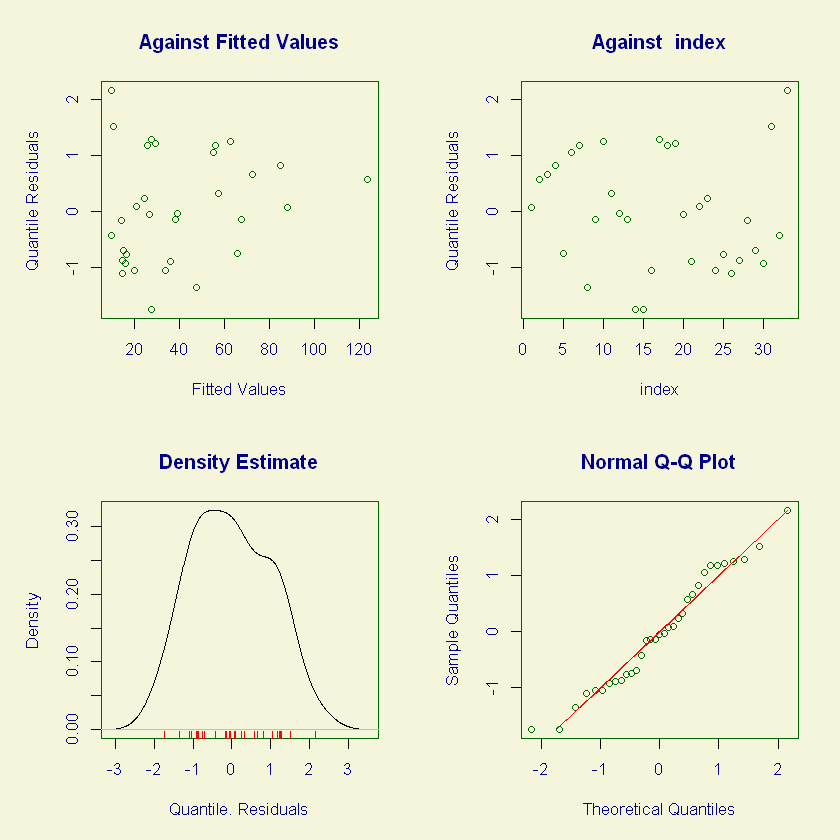

In [13]:
plot(aj3_sobrev)

### `wp` (worm plot)

É um QQ-plot *sem a tendência*: no eixo vertical fica a diferença entre o quantil empírico e o teórico dos resíduos. Com o modelo bem ajustado, os pontos ficam espalhados em torno da linha horizontal zero e **dentro das duas curvas tracejadas** (intervalo de 95%).

**Como interpretar formas típicas:**
- pontos fora das curvas → desajuste da distribuição;
- nível deslocado para cima ou para baixo → média mal ajustada;
- inclinação → variância mal ajustada (dispersão);
- forma de U ou U invertido → assimetria mal ajustada;
- forma de S → curtose mal ajustada (caudas).

Com só 33 observações, as bandas são largas, então pequenas formas não chegam a ser evidência de problema.

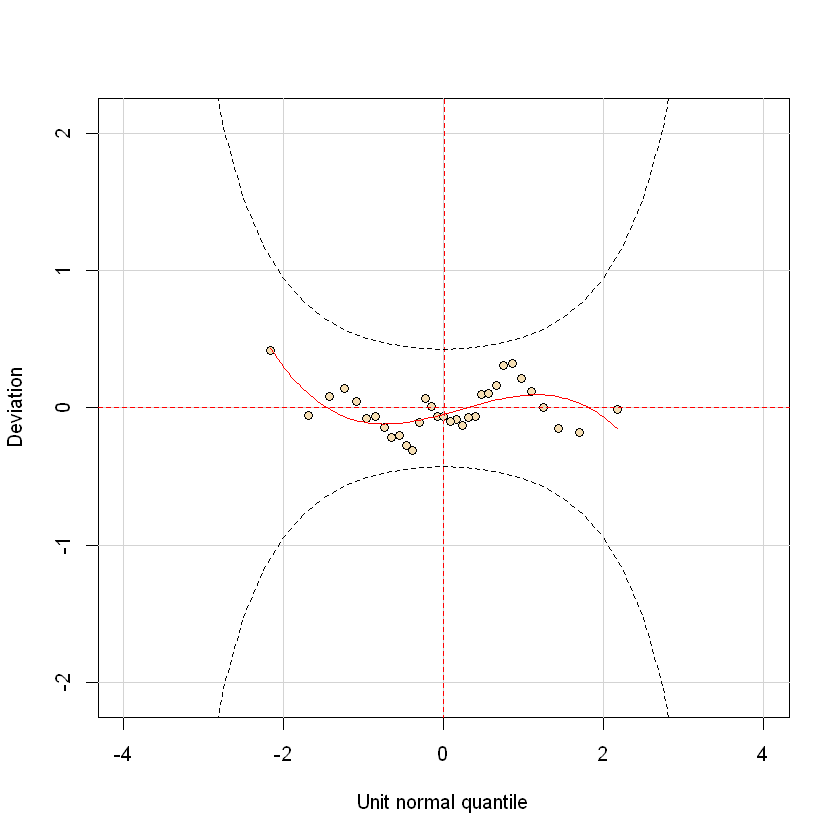

In [14]:
wp(aj3_sobrev)

### `term.plot`

Mostra o **efeito parcial** de cada termo no preditor linear de $\mu$ (escala log), com banda de erro padrão e resíduos parciais.

**Como interpretar:**
- **log(WBC):** uma reta decrescente com inclinação ≈ −0,30, mostrando que o log do tempo médio cai linearmente com log(WBC). Se os resíduos parciais seguirem a reta, a forma linear (na escala log) está adequada; uma curvatura sugeriria outra forma funcional.
- **AG:** como AG é 0/1, o gráfico é uma reta entre os dois grupos; a diferença de altura entre AG = 1 e AG = 0 é ≈ 1,02, o efeito do grupo na escala log.

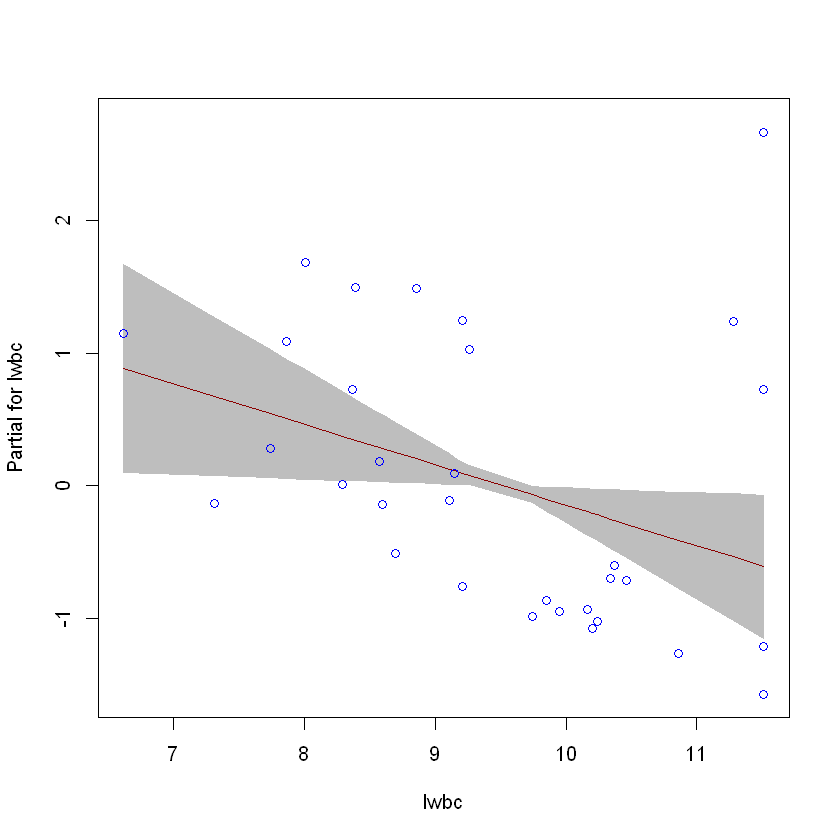

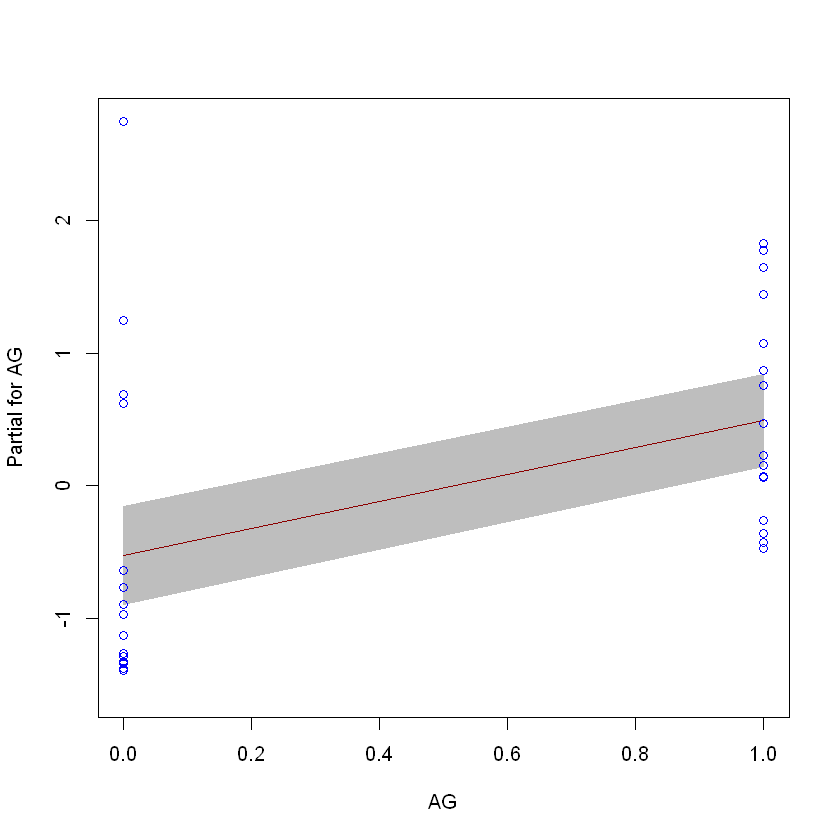

In [15]:
term.plot(aj3_sobrev, what="mu", partial.resid=TRUE, se=TRUE, ask=FALSE,col.res= rgb(0, 0, 1, 1))

## 6. Interpretação das estimativas

Com ligação log, $\mu = \exp(\beta_0)\cdot \exp(\beta_1)^{\log(\text{WBC})}\cdot\exp(\beta_2)^{\text{AG}}$, então os efeitos são **multiplicativos** no tempo médio de sobrevivência.

In [16]:
# Efeitos multiplicativos no tempo médio
exp(coefficients(aj2_sobrev))

# Efeito de dobrar o WBC: 2^beta1
2^coefficients(aj2_sobrev)["lwbc"]

# Intervalos de confiança de 95% (escala original)
exp(confint.default(aj2_sobrev))

(Intercept)        lwbc          AG 
335.4291990   0.7375655   2.7666722

lwbc 
0.8097787

,2.5 %,97.5 %
(Intercept),23.8547320,4716.5798133
lwbc,0.5632991,0.9657443
AG,1.3549891,5.6491044


**Modelo ajustado:**

$$\hat\mu = \exp\{5{,}815 - 0{,}304\,\log(\text{WBC}) + 1{,}018\,\text{AG}\}.$$

- **AG:** $e^{1{,}018} \approx 2{,}77$. Para um mesmo número de células brancas, o tempo médio de sobrevivência de um paciente **AG positivo é cerca de 2,8 vezes** o de um paciente AG negativo.
- **log(WBC):** $e^{-0{,}304} \approx 0{,}74$. Cada aumento de uma unidade em $\log(\text{WBC})$ (isto é, WBC multiplicado por $e \approx 2{,}7$) multiplica o tempo médio por 0,74, uma **redução de cerca de 26%**, mantido o grupo AG. De forma mais intuitiva: **dobrar o WBC** multiplica o tempo médio por $2^{-0{,}304} \approx 0{,}81$, uma redução de cerca de 19%.
- **Intercepto:** $e^{5{,}815} \approx 335$ semanas seria o tempo médio de um paciente AG negativo com WBC = 1 ($\log(\text{WBC}) = 0$). Esse valor não tem interpretação prática, pois está muito fora do intervalo observado de WBC.
- **Dispersão:** $\hat\phi \approx 0{,}92$, ou seja, coeficiente de variação $\approx 1/\sqrt{0{,}92} \approx 1{,}04$. O desvio padrão do tempo é praticamente igual à média, o que mostra a grande variabilidade da sobrevivência mesmo para pacientes com o mesmo perfil.

**Em resumo:** a presença da característica morfológica (AG positivo) está associada a maior sobrevivência, e um número maior de células brancas no diagnóstico está associado a menor sobrevivência.